# FinRisk AI — Exploratory Data Analysis (EDA)
## Default of Credit Card Clients Dataset (UCI Machine Learning Repository)

**Project:** FinRisk AI  
**Dataset:** 30,000 credit card clients in Taiwan (April 2005 – September 2005)  
**Objective:** Comprehensive exploratory data analysis to uncover risk drivers, assess data quality, evaluate statistical hypotheses, and inform feature engineering and modeling.

---
### Table of Contents:
1. **Section 1: Data Overview** — Shape, schemas, memory usage, target class balance.
2. **Section 2: Missing Values & Data Quality** — Null values, anomalies, undocumented categories.
3. **Section 3: Univariate Analysis** — Distributions, skewness, kurtosis, boxplots.
4. **Section 4: Bivariate Analysis** — Default rate across demographics, payment delay patterns, correlation analysis.
5. **Section 5: Outlier Detection** — IQR & Z-score methodologies and percentages.
6. **Section 6: Statistical Hypothesis Testing** — Chi-squared tests, Mann-Whitney U, Welch's t-test, Kruskal-Wallis ANOVA.
7. **Section 7: Feature Relationships** — Payment trends over time, bill vs. payment scatter, credit utilization analysis.
8. **Section 8: Key Findings & Modeling Recommendations** — Synthesis of insights, feature engineering roadmap, modeling strategy.


### Setup and Libraries
We import data manipulation, visualization, and statistical modeling libraries, setting standard plot styles and figure dimensions.

In [1]:
%matplotlib inline

import os
import sys
import warnings
from pathlib import Path
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# Define directories
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "FINRISK AI" else Path(".").resolve()
PLOTS_DIR = PROJECT_ROOT / "outputs" / "eda_plots"
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "credit_default.csv"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Plot settings
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "savefig.dpi": 150,
})

def save_and_show(fig_name: str):
    save_path = PLOTS_DIR / f"{fig_name}.png"
    plt.savefig(save_path)
    plt.show()
    print(f"Plot saved to: {save_path.relative_to(PROJECT_ROOT) if PROJECT_ROOT in save_path.parents else save_path}")


### Data Ingestion
Loading the dataset from `data/raw/credit_default.csv` (downloaded from UCI ML Repository). We drop the administrative `ID` column and normalize target name to `default`.

In [2]:
# Ingestion and standardization
df = pd.read_csv(RAW_DATA_PATH)

# Standardize target column
if "default payment next month" in df.columns:
    df = df.rename(columns={"default payment next month": "default"})
elif "default.payment.next.month" in df.columns:
    df = df.rename(columns={"default.payment.next.month": "default"})

if "ID" in df.columns:
    df = df.drop(columns=["ID"])

print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()


Dataset Shape: 30,000 rows × 24 columns


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Section 1: Data Overview
We examine column types, memory consumption, descriptive statistics, and the target distribution.

In [3]:
# Schema & Memory Profile
print("--- Data Info ---")
df.info(memory_usage="deep")


--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64

In [4]:
# Descriptive Statistics
df.describe().T


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


Non-Defaulters (0): 23,364 (77.88%)
Defaulters (1):     6,636 (22.12%)


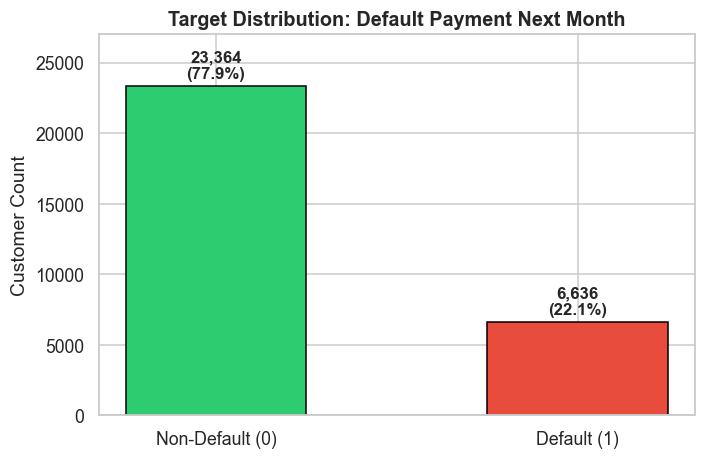

Plot saved to: outputs\eda_plots\01_target_distribution.png


In [5]:
# Target Variable Distribution
target_counts = df["default"].value_counts()
target_pcts = df["default"].value_counts(normalize=True) * 100

print(f"Non-Defaulters (0): {target_counts[0]:,} ({target_pcts[0]:.2f}%)")
print(f"Defaulters (1):     {target_counts[1]:,} ({target_pcts[1]:.2f}%)")

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#2ecc71", "#e74c3c"]
bars = ax.bar(["Non-Default (0)", "Default (1)"], [target_counts[0], target_counts[1]], color=colors, edgecolor="black", width=0.5)

for bar, cnt, pct in zip(bars, [target_counts[0], target_counts[1]], [target_pcts[0], target_pcts[1]]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f"{cnt:,}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold", fontsize=11)

ax.set_ylim(0, 27000)
ax.set_title("Target Distribution: Default Payment Next Month", fontsize=13, fontweight="bold")
ax.set_ylabel("Customer Count")
save_and_show("01_target_distribution")


## Section 2: Missing Values & Data Quality
Checking for null values, duplicates, and undocumented category codes in `EDUCATION` and `MARRIAGE`.

In [6]:
# Missing values check
missing = df.isnull().sum()
print("Missing values per column:")
if missing.sum() == 0:
    print("✓ Perfect data completeness: 0 missing values across all 30,000 rows.")
else:
    print(missing[missing > 0])

# Duplicate rows check
print(f"Duplicate rows detected: {df.duplicated().sum()}")


Missing values per column:
✓ Perfect data completeness: 0 missing values across all 30,000 rows.
Duplicate rows detected: 35


In [7]:
# Data Quality: Undocumented Categorical Values
# According to UCI dataset documentation:
# EDUCATION: 1 = graduate school; 2 = university; 3 = high school; 4 = others
# MARRIAGE: 1 = married; 2 = single; 3 = others

print("--- EDUCATION Value Counts ---")
print(df["EDUCATION"].value_counts().sort_index())
print("\nNotice codes 0, 5, 6 are undocumented in the original data dictionary.")

print("\n--- MARRIAGE Value Counts ---")
print(df["MARRIAGE"].value_counts().sort_index())
print("\nNotice code 0 is undocumented in the original data dictionary.")

# Default rates for undocumented categories
print("\nDefault Rate by EDUCATION code:")
print(df.groupby("EDUCATION")["default"].agg(["mean", "count"]).assign(default_rate=lambda x: x["mean"]*100))

print("\nDefault Rate by MARRIAGE code:")
print(df.groupby("MARRIAGE")["default"].agg(["mean", "count"]).assign(default_rate=lambda x: x["mean"]*100))


--- EDUCATION Value Counts ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Notice codes 0, 5, 6 are undocumented in the original data dictionary.

--- MARRIAGE Value Counts ---
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Notice code 0 is undocumented in the original data dictionary.

Default Rate by EDUCATION code:
               mean  count  default_rate
EDUCATION                               
0          0.000000     14      0.000000
1          0.192348  10585     19.234766
2          0.237349  14030     23.734854
3          0.251576   4917     25.157616
4          0.056911    123      5.691057
5          0.064286    280      6.428571
6          0.156863     51     15.686275

Default Rate by MARRIAGE code:
              mean  count  default_rate
MARRIAGE                               
0         0.092593     54      9.259259
1         0.234717  13659     23.471704
2         0.2092

## Section 3: Univariate Analysis
Analyzing continuous feature distributions (KDE, histograms, skewness, kurtosis) and categorical value frequencies.

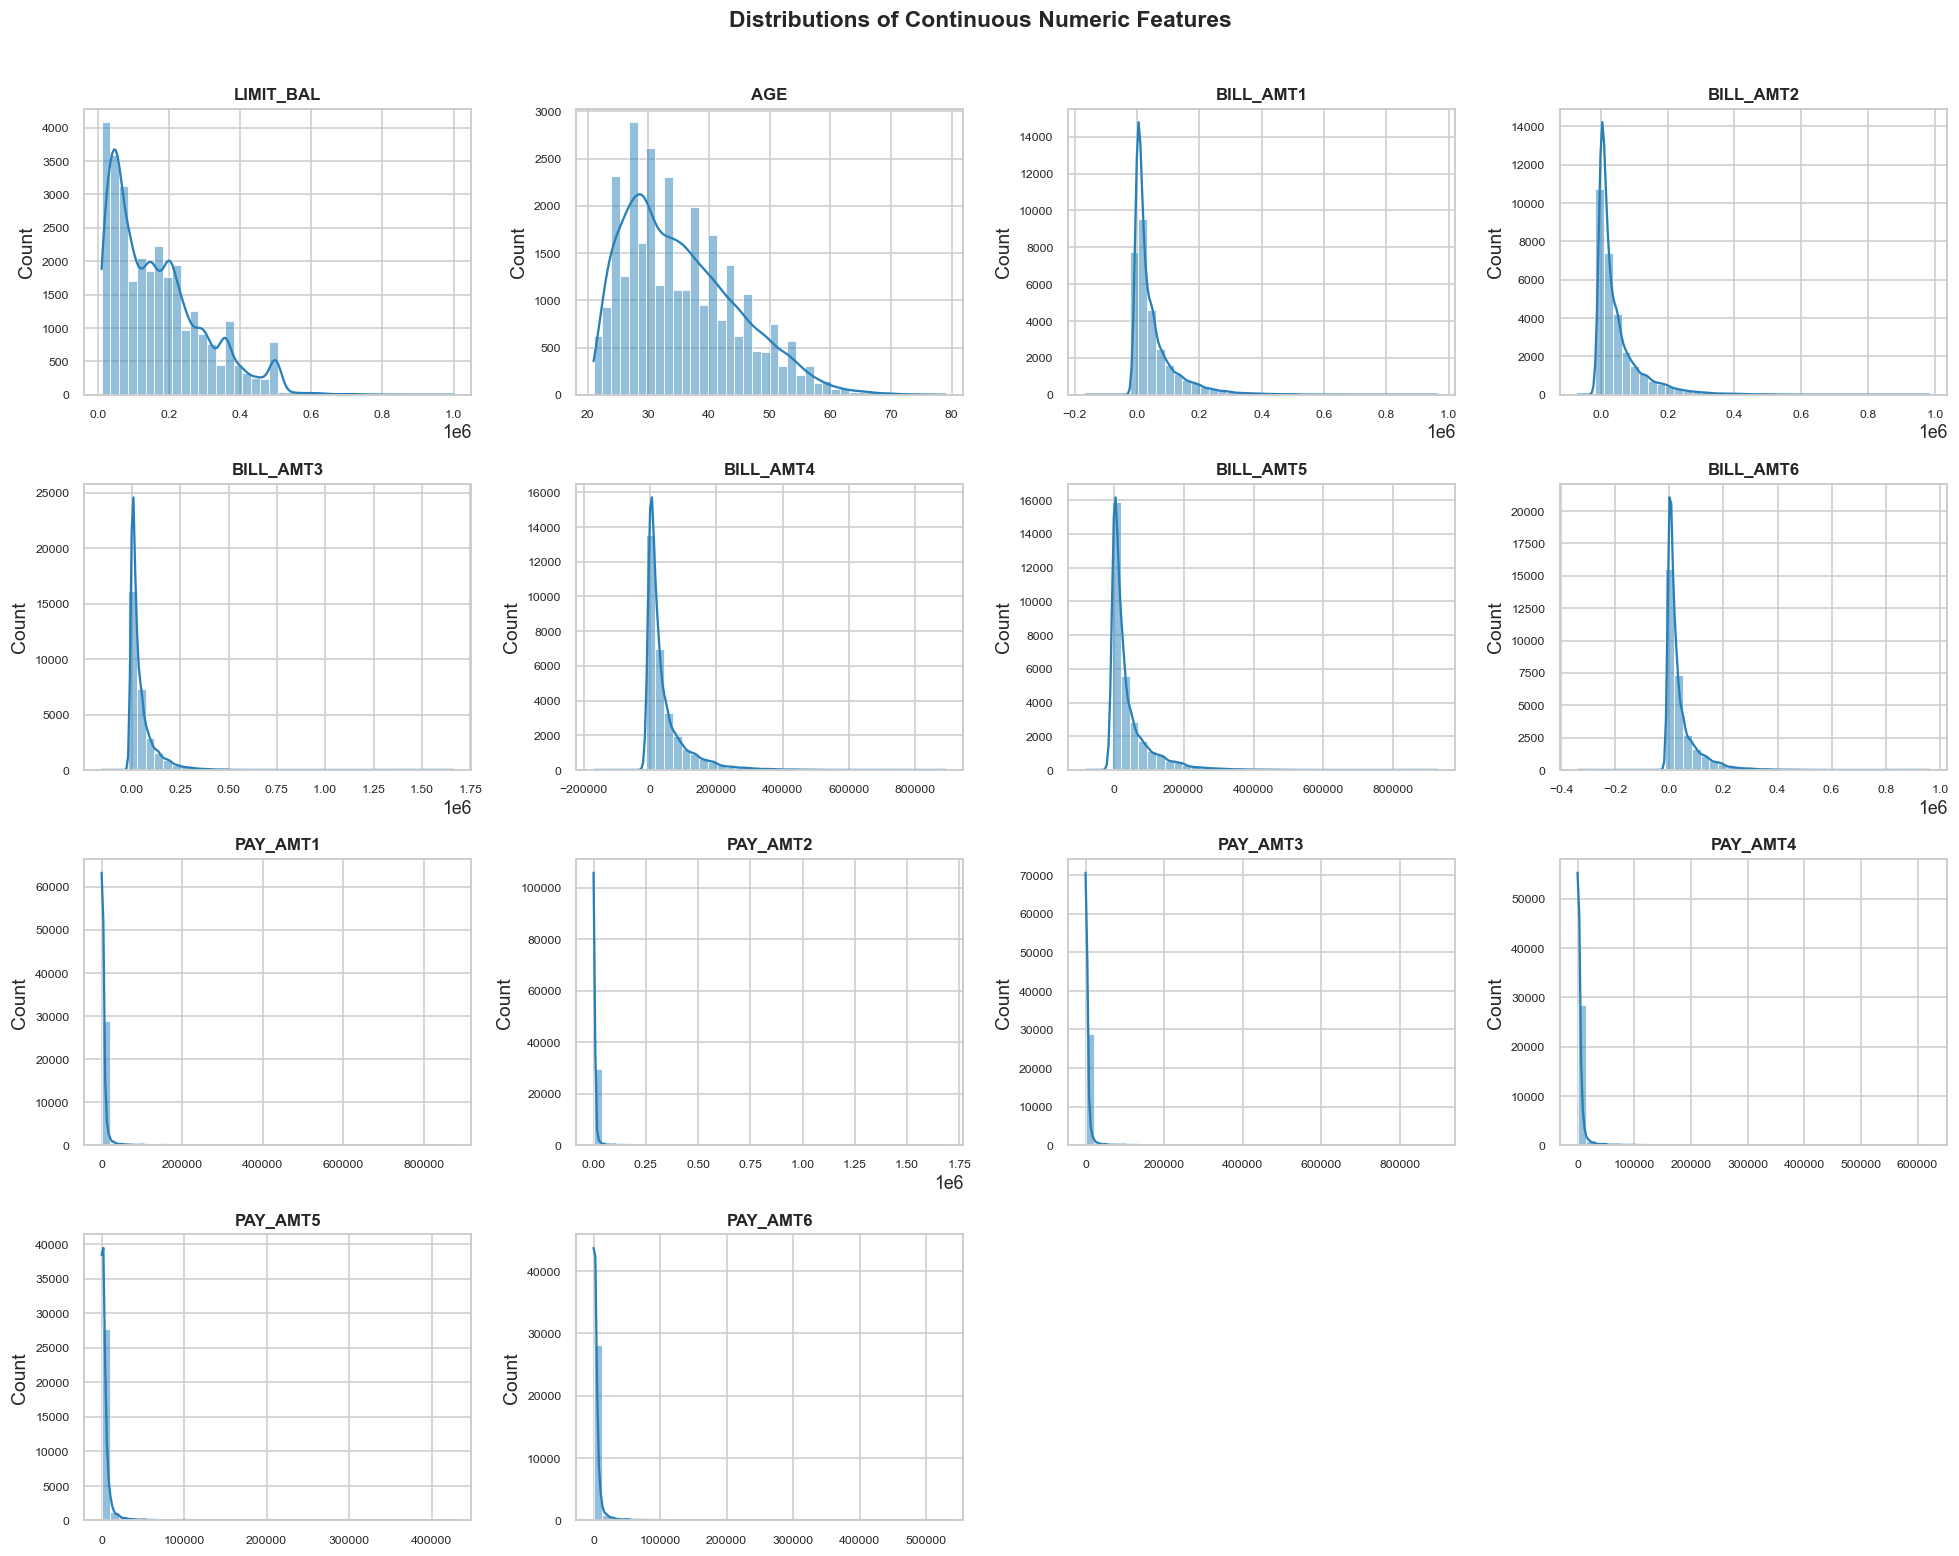

Plot saved to: outputs\eda_plots\03_numeric_distributions.png


In [8]:
numeric_cols = ["LIMIT_BAL", "AGE"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]

# Histograms with KDE for continuous numeric features
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[idx], color="#2980b9", bins=40)
    axes[idx].set_title(col, fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("")
    axes[idx].tick_params(labelsize=8)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distributions of Continuous Numeric Features", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
save_and_show("03_numeric_distributions")


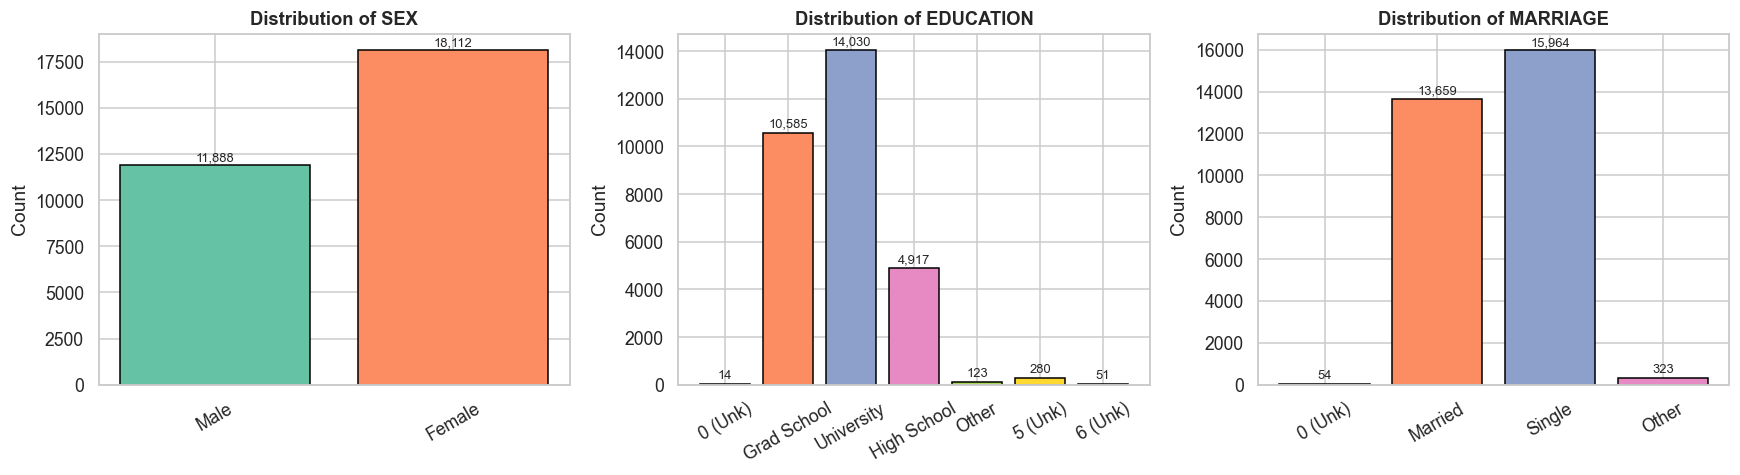

Plot saved to: outputs\eda_plots\03_categorical_distributions.png


In [9]:
# Categorical feature distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

labels_map = {
    "SEX": {1: "Male", 2: "Female"},
    "EDUCATION": {0: "0 (Unk)", 1: "Grad School", 2: "University", 3: "High School", 4: "Other", 5: "5 (Unk)", 6: "6 (Unk)"},
    "MARRIAGE": {0: "0 (Unk)", 1: "Married", 2: "Single", 3: "Other"}
}

for idx, col in enumerate(["SEX", "EDUCATION", "MARRIAGE"]):
    vc = df[col].value_counts().sort_index()
    names = [labels_map[col].get(k, str(k)) for k in vc.index]
    bars = axes[idx].bar(names, vc.values, color=sns.color_palette("Set2", len(vc)), edgecolor="black")
    axes[idx].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[idx].set_ylabel("Count")
    axes[idx].tick_params(axis="x", rotation=30)
    for bar, cnt in zip(bars, vc.values):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, f"{cnt:,}", ha="center", va="bottom", fontsize=8.5)

plt.tight_layout()
save_and_show("03_categorical_distributions")


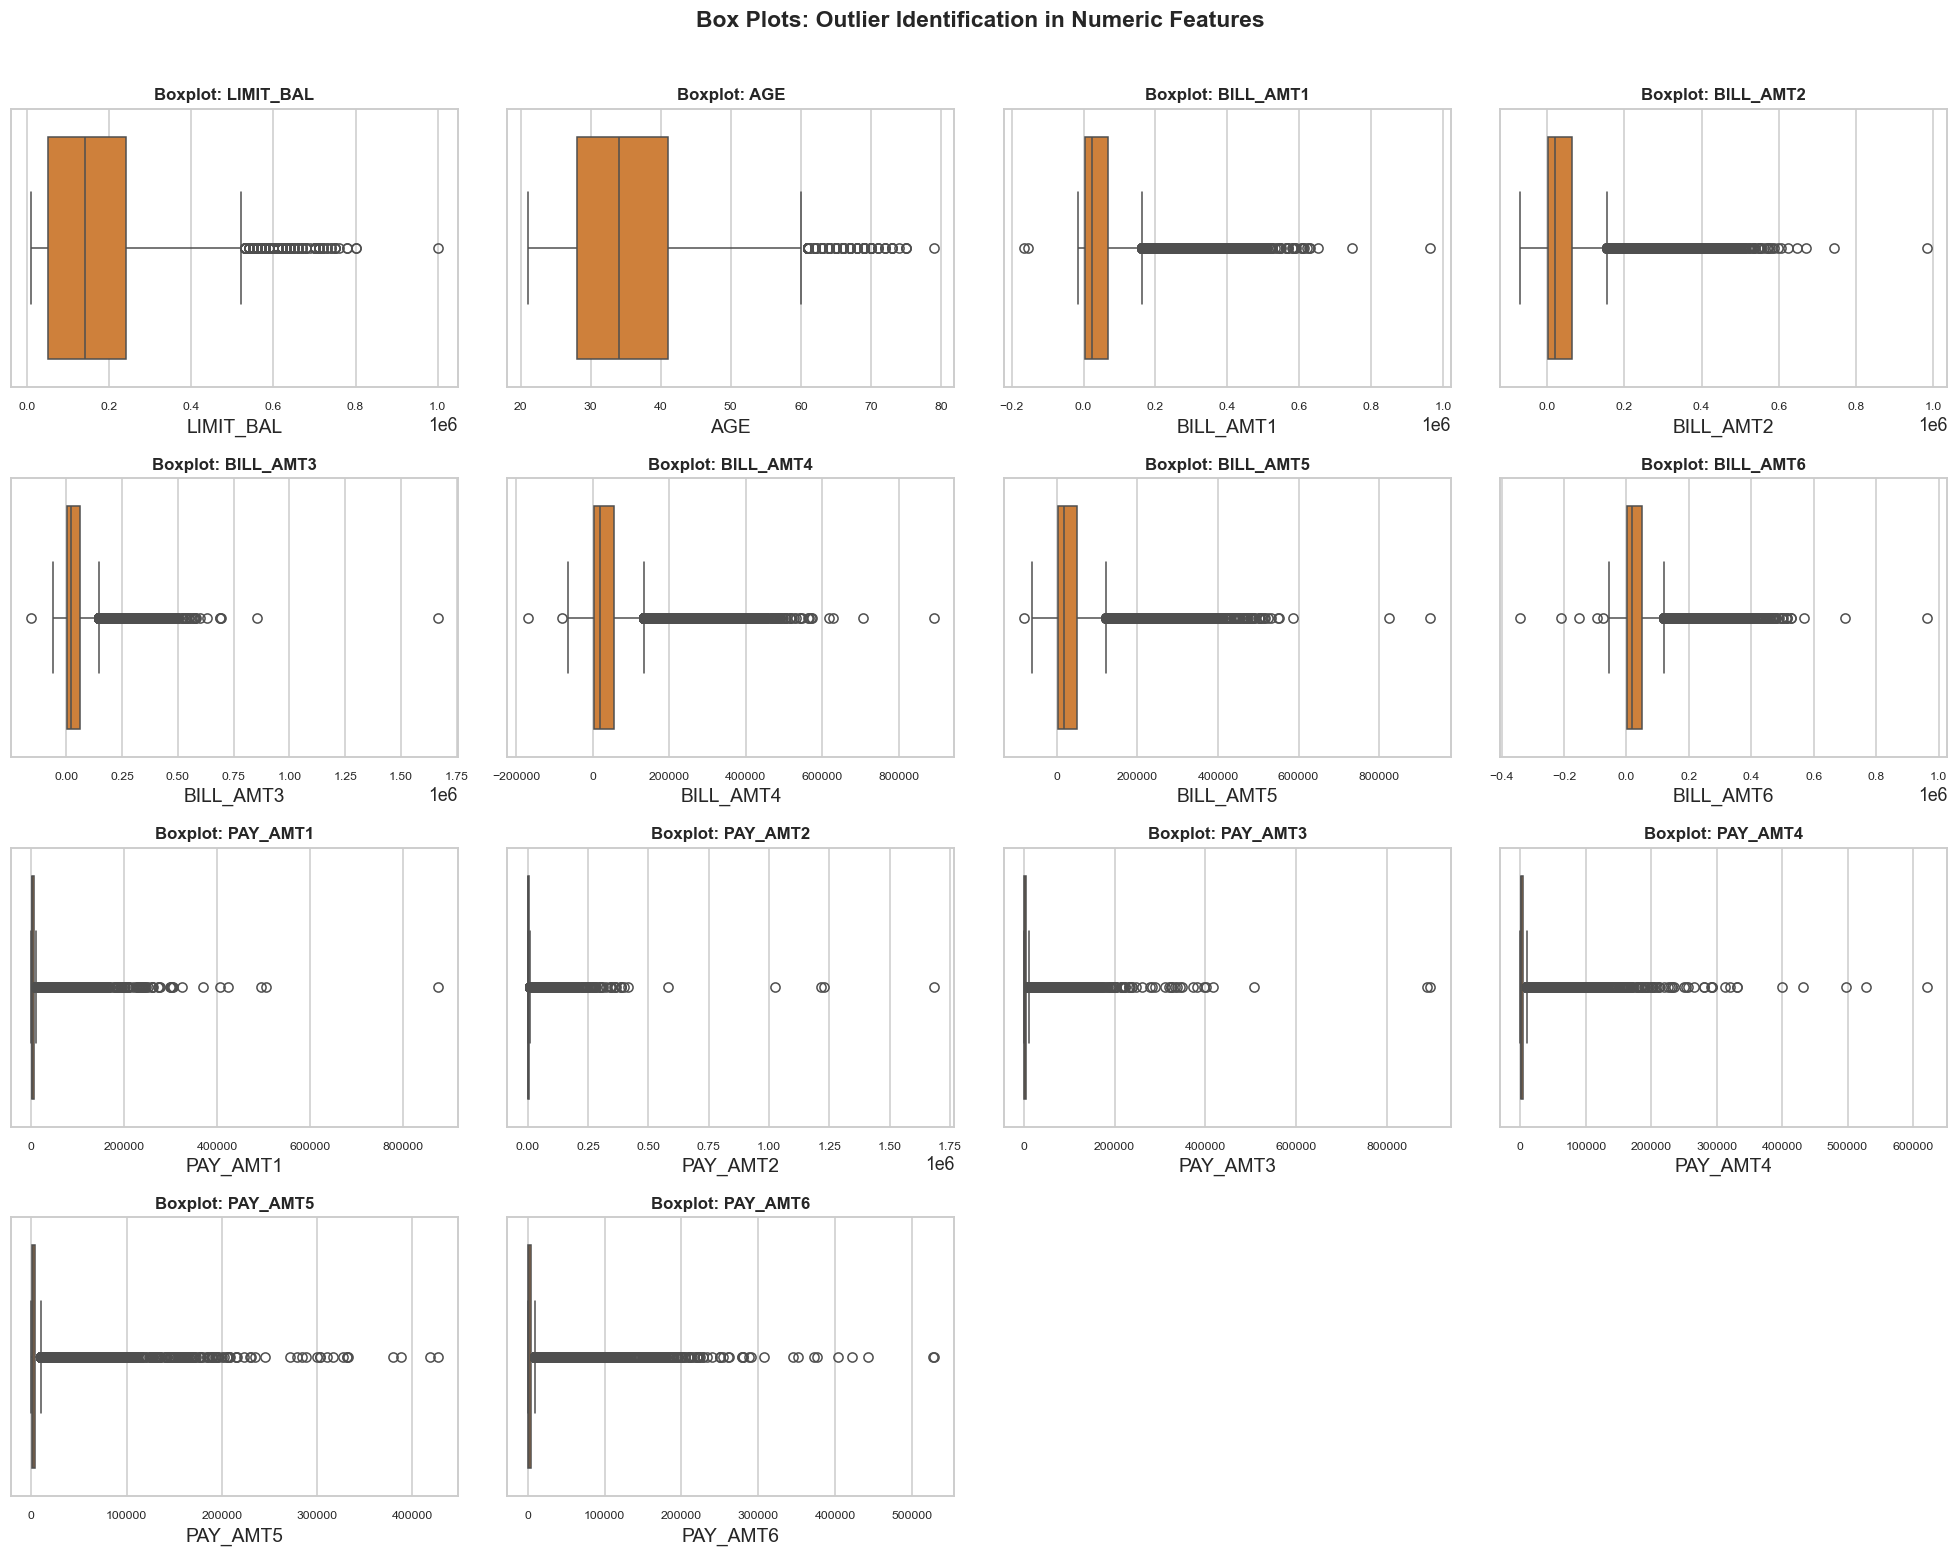

Plot saved to: outputs\eda_plots\03_boxplots.png


In [10]:
# Box plots for continuous features to visualize outliers
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[idx], color="#e67e22")
    axes[idx].set_title(f"Boxplot: {col}", fontsize=11, fontweight="bold")
    axes[idx].tick_params(labelsize=8)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Box Plots: Outlier Identification in Numeric Features", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
save_and_show("03_boxplots")


In [11]:
# Skewness & Kurtosis Table
stats_summary = []
pay_cols = [f"PAY_{i}" for i in [0, 2, 3, 4, 5, 6] if f"PAY_{i}" in df.columns]

for col in numeric_cols + pay_cols:
    stats_summary.append({
        "Feature": col,
        "Mean": df[col].mean(),
        "Median": df[col].median(),
        "Std": df[col].std(),
        "Skewness": df[col].skew(),
        "Kurtosis": df[col].kurtosis()
    })

stats_df = pd.DataFrame(stats_summary)
print("--- Skewness & Kurtosis Summary ---")
stats_df.sort_values(by="Skewness", ascending=False).reset_index(drop=True)


--- Skewness & Kurtosis Summary ---


,Feature,Mean,Median,Std,Skewness,Kurtosis
0,PAY_AMT2,5921.163500,2009.0,23040.870402,30.453817,1641.631911
1,PAY_AMT3,5225.681500,1800.0,17606.961470,17.216635,564.311229
2,PAY_AMT1,5663.580500,2100.0,16563.280354,14.668364,415.254743
3,PAY_AMT4,4826.076867,1500.0,15666.159744,12.904985,277.333768
4,PAY_AMT5,4799.387633,1500.0,15278.305679,11.127417,180.063940
5,PAY_AMT6,5215.502567,1500.0,17777.465775,10.640727,167.161430
6,BILL_AMT3,47013.154800,20088.5,69349.387427,3.087830,19.783255
7,BILL_AMT5,40311.400967,18104.5,60797.155770,2.876380,12.305881
8,BILL_AMT6,38871.760400,17071.0,59554.107537,2.846645,12.270705
9,BILL_AMT4,43262.948967,19052.0,64332.856134,2.821965,11.309325


## Section 4: Bivariate Analysis
Examining the relationship between predictors and default risk: demographics, age groups, payment status histories, and correlation patterns.

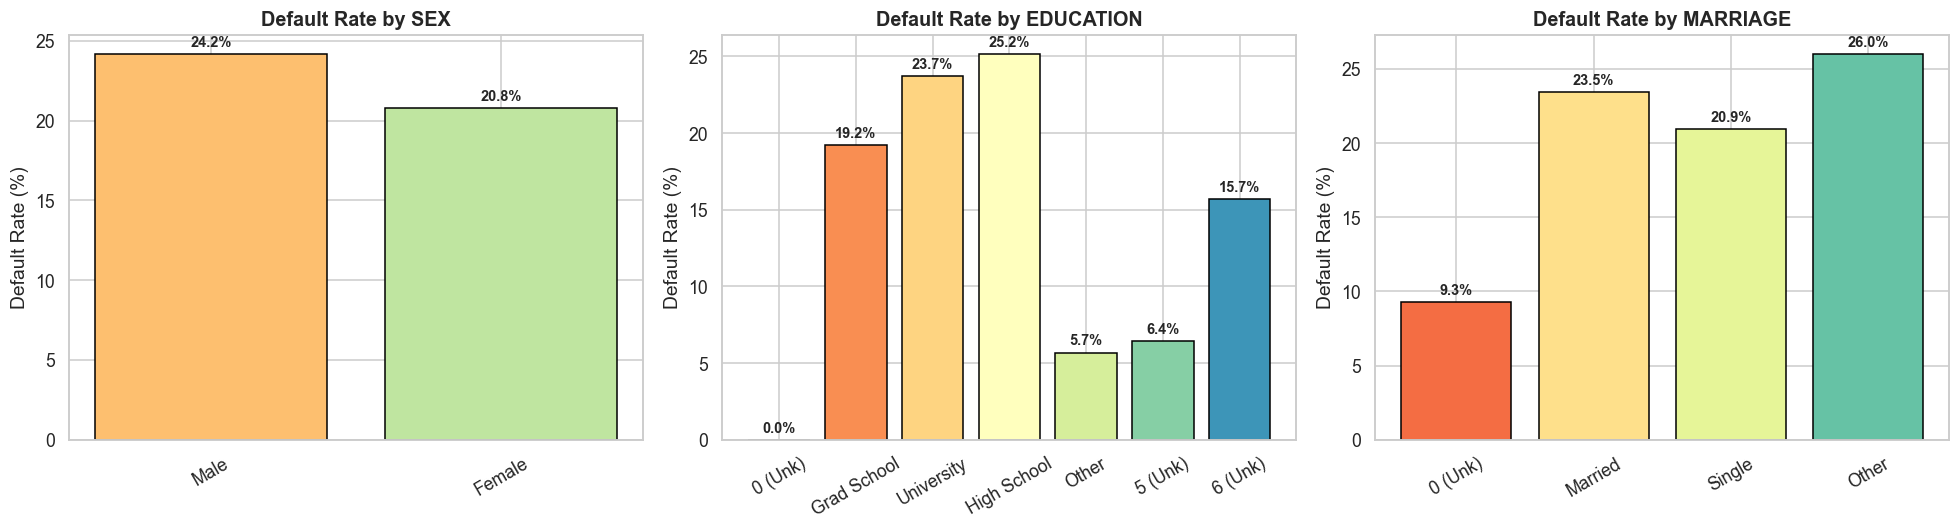

Plot saved to: outputs\eda_plots\04_default_rate_by_categorical.png


In [12]:
# Default rates across categorical demographics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, col in enumerate(["SEX", "EDUCATION", "MARRIAGE"]):
    grouped = df.groupby(col)["default"].mean() * 100
    names = [labels_map[col].get(k, str(k)) for k in grouped.index]
    bars = axes[idx].bar(names, grouped.values, color=sns.color_palette("Spectral", len(grouped)), edgecolor="black")
    axes[idx].set_title(f"Default Rate by {col}", fontsize=13, fontweight="bold")
    axes[idx].set_ylabel("Default Rate (%)")
    axes[idx].tick_params(axis="x", rotation=30)
    for bar, rate in zip(bars, grouped.values):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{rate:.1f}%", ha="center", va="bottom", fontweight="bold", fontsize=9.5)

plt.tight_layout()
save_and_show("04_default_rate_by_categorical")


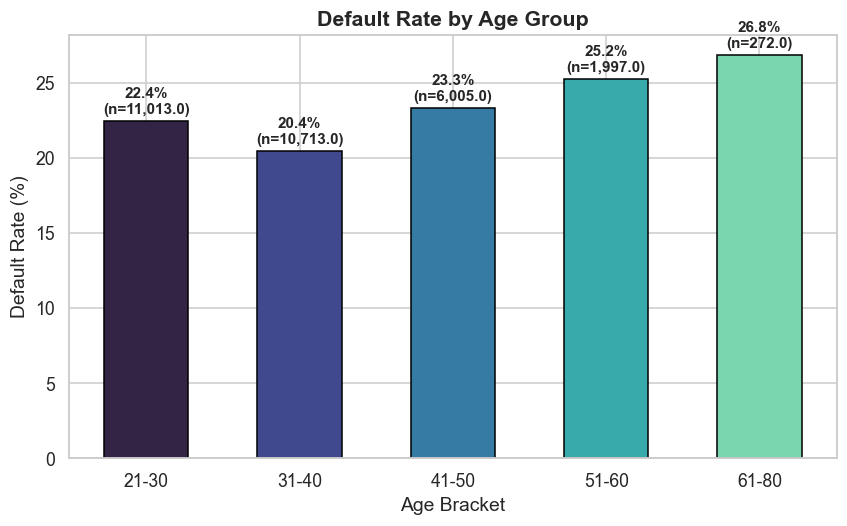

Plot saved to: outputs\eda_plots\04_default_rate_by_age.png


In [13]:
# Default Rate by AGE Groups
df["AGE_GROUP"] = pd.cut(df["AGE"], bins=[20, 30, 40, 50, 60, 80], labels=["21-30", "31-40", "41-50", "51-60", "61-80"])
age_grp = df.groupby("AGE_GROUP", observed=True)["default"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(age_grp.index.astype(str), age_grp["mean"] * 100, color=sns.color_palette("mako", len(age_grp)), edgecolor="black", width=0.55)

for bar, (_, row) in zip(bars, age_grp.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{row['mean']*100:.1f}%\n(n={row['count']:,})", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Default Rate by Age Group", fontsize=14, fontweight="bold")
ax.set_ylabel("Default Rate (%)")
ax.set_xlabel("Age Bracket")
save_and_show("04_default_rate_by_age")
df.drop(columns=["AGE_GROUP"], inplace=True)


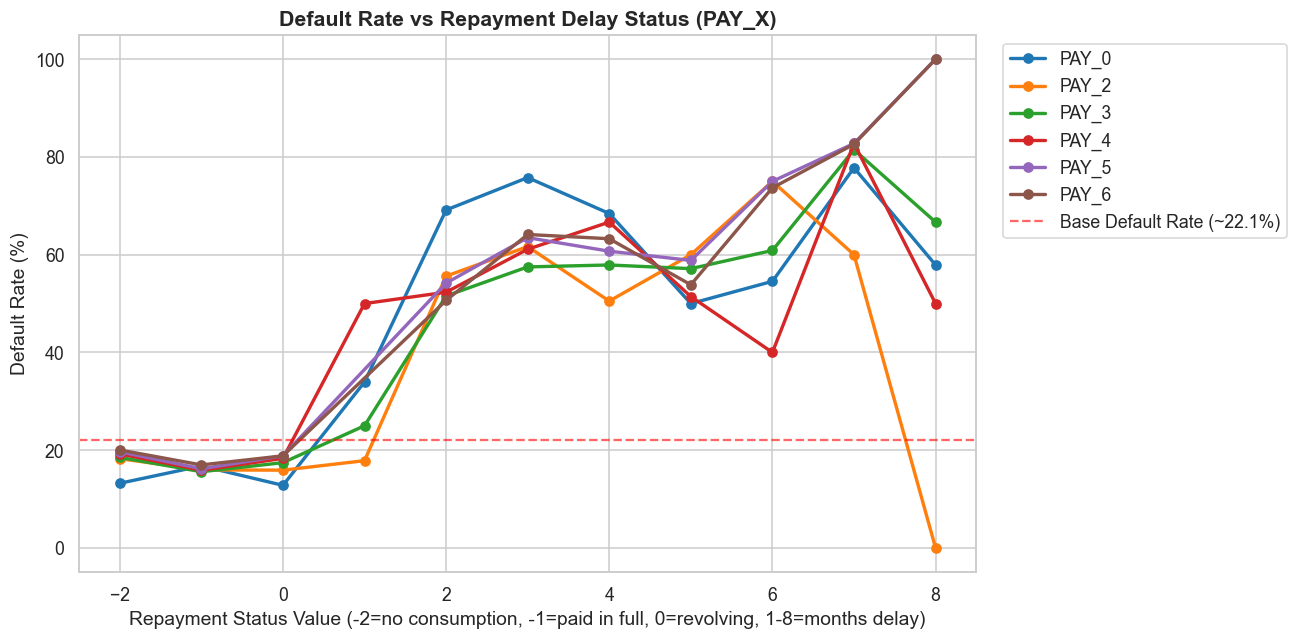

Plot saved to: outputs\eda_plots\04_default_rate_by_payment_delay.png


In [14]:
# Default rate by Payment Delay Status (PAY_0 to PAY_6)
pay_cols = [c for c in df.columns if c.startswith("PAY_") and c.replace("PAY_", "").isdigit()]
pay_cols = sorted(pay_cols, key=lambda x: int(x.split("_")[1]))

fig, ax = plt.subplots(figsize=(12, 6))
colors_pay = sns.color_palette("tab10", len(pay_cols))

for idx, col in enumerate(pay_cols):
    rate_by_delay = df.groupby(col)["default"].mean() * 100
    ax.plot(rate_by_delay.index, rate_by_delay.values, marker="o", label=col, color=colors_pay[idx], linewidth=2.2)

ax.set_title("Default Rate vs Repayment Delay Status (PAY_X)", fontsize=14, fontweight="bold")
ax.set_xlabel("Repayment Status Value (-2=no consumption, -1=paid in full, 0=revolving, 1-8=months delay)")
ax.set_ylabel("Default Rate (%)")
ax.set_xlim(-2.5, 8.5)
ax.axhline(22.1, color="red", linestyle="--", alpha=0.6, label="Base Default Rate (~22.1%)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_and_show("04_default_rate_by_payment_delay")


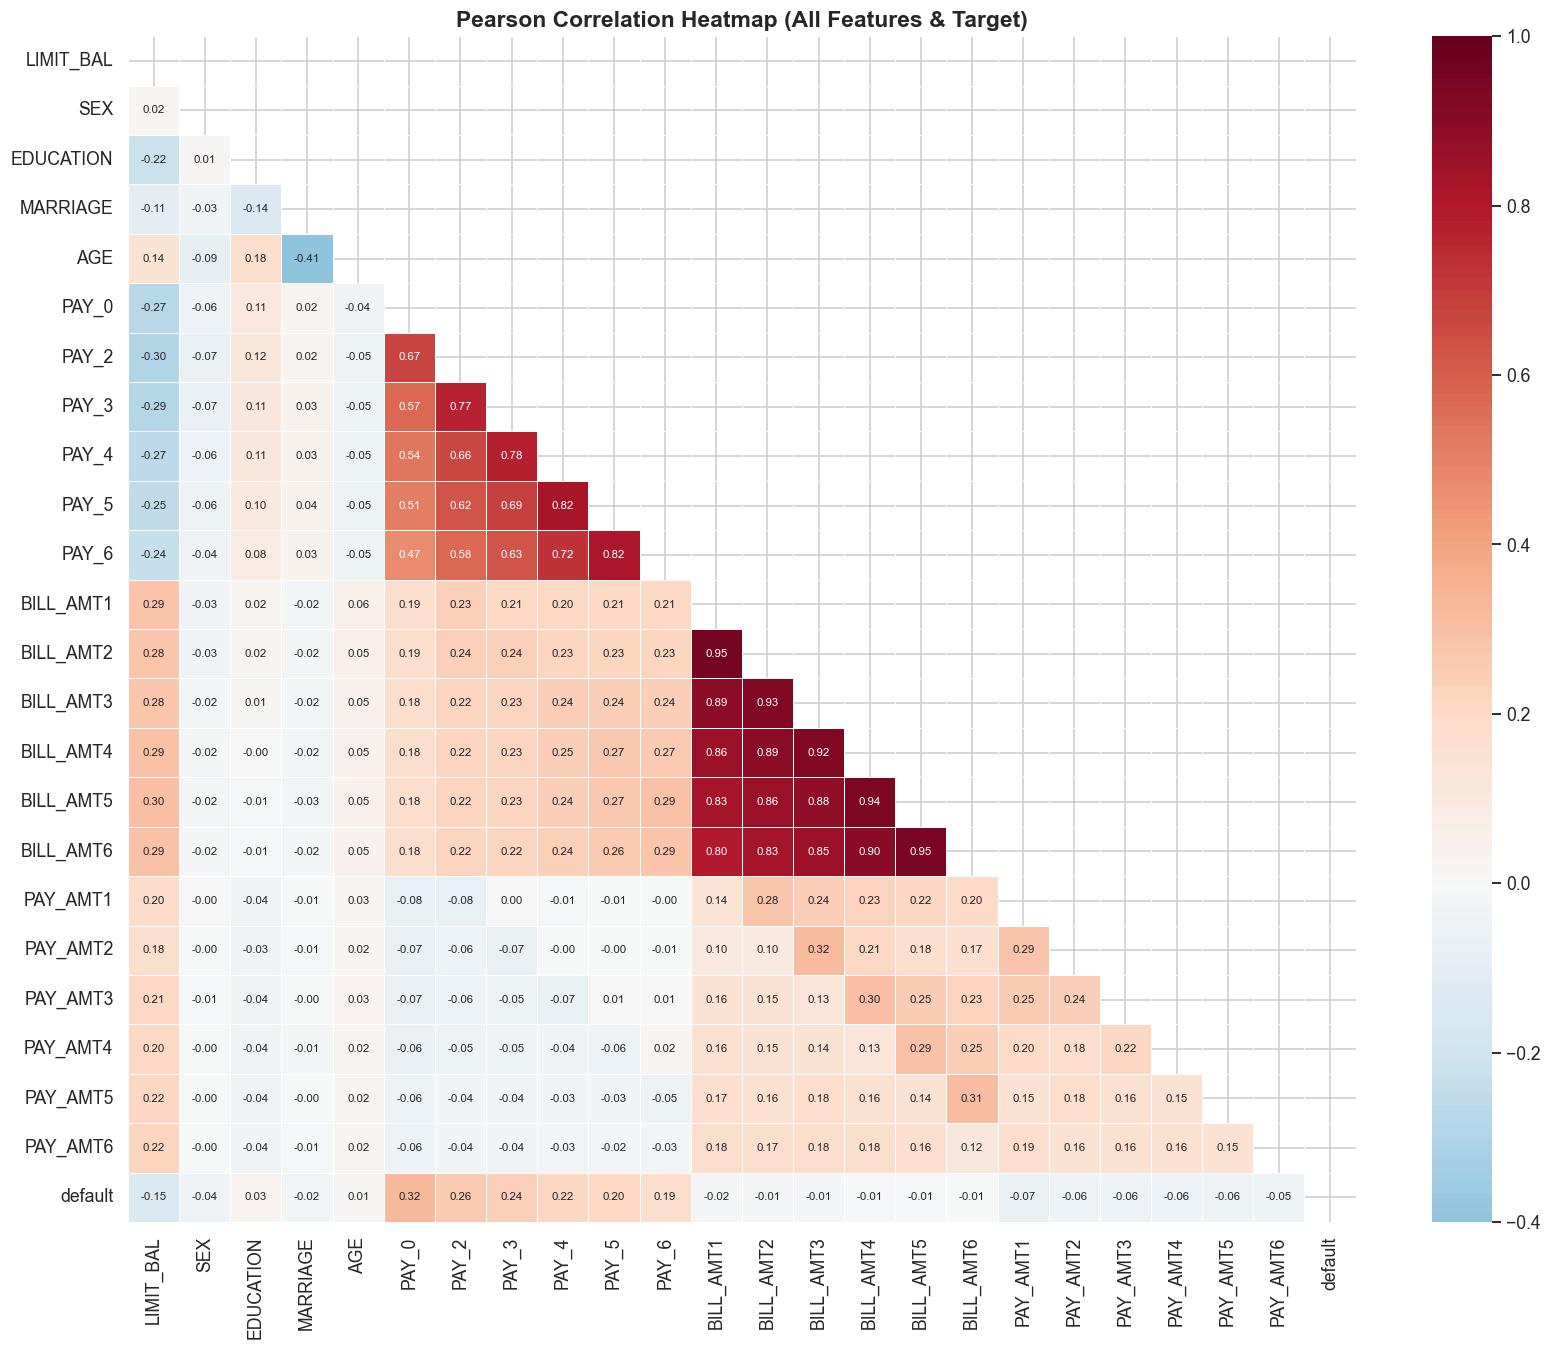

Plot saved to: outputs\eda_plots\04_correlation_matrix.png
--- Top 10 Features Correlated with Target (Absolute r) ---
  PAY_0           r = +0.3248 (|r| = 0.3248)
  PAY_2           r = +0.2636 (|r| = 0.2636)
  PAY_3           r = +0.2353 (|r| = 0.2353)
  PAY_4           r = +0.2166 (|r| = 0.2166)
  PAY_5           r = +0.2041 (|r| = 0.2041)
  PAY_6           r = +0.1869 (|r| = 0.1869)
  LIMIT_BAL       r = -0.1535 (|r| = 0.1535)
  PAY_AMT1        r = -0.0729 (|r| = 0.0729)
  PAY_AMT2        r = -0.0586 (|r| = 0.0586)
  PAY_AMT4        r = -0.0568 (|r| = 0.0568)


In [15]:
# Correlation Matrix Heatmap & Target Association
corr = df.corr()

fig, ax = plt.subplots(figsize=(18, 14))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5, ax=ax, annot_kws={"size": 7.5}, vmin=-0.4, vmax=1.0)
ax.set_title("Pearson Correlation Heatmap (All Features & Target)", fontsize=15, fontweight="bold")
save_and_show("04_correlation_matrix")

print("--- Top 10 Features Correlated with Target (Absolute r) ---")
target_corr = corr["default"].drop("default").abs().sort_values(ascending=False).head(10)
for col, abs_r in target_corr.items():
    print(f"  {col:<15} r = {corr.loc[col, 'default']:+.4f} (|r| = {abs_r:.4f})")


## Section 5: Outlier Detection
Quantifying outliers across continuous monetary variables (`LIMIT_BAL`, `BILL_AMT1-6`, `PAY_AMT1-6`) using IQR fences and Z-scores (|z| > 3).

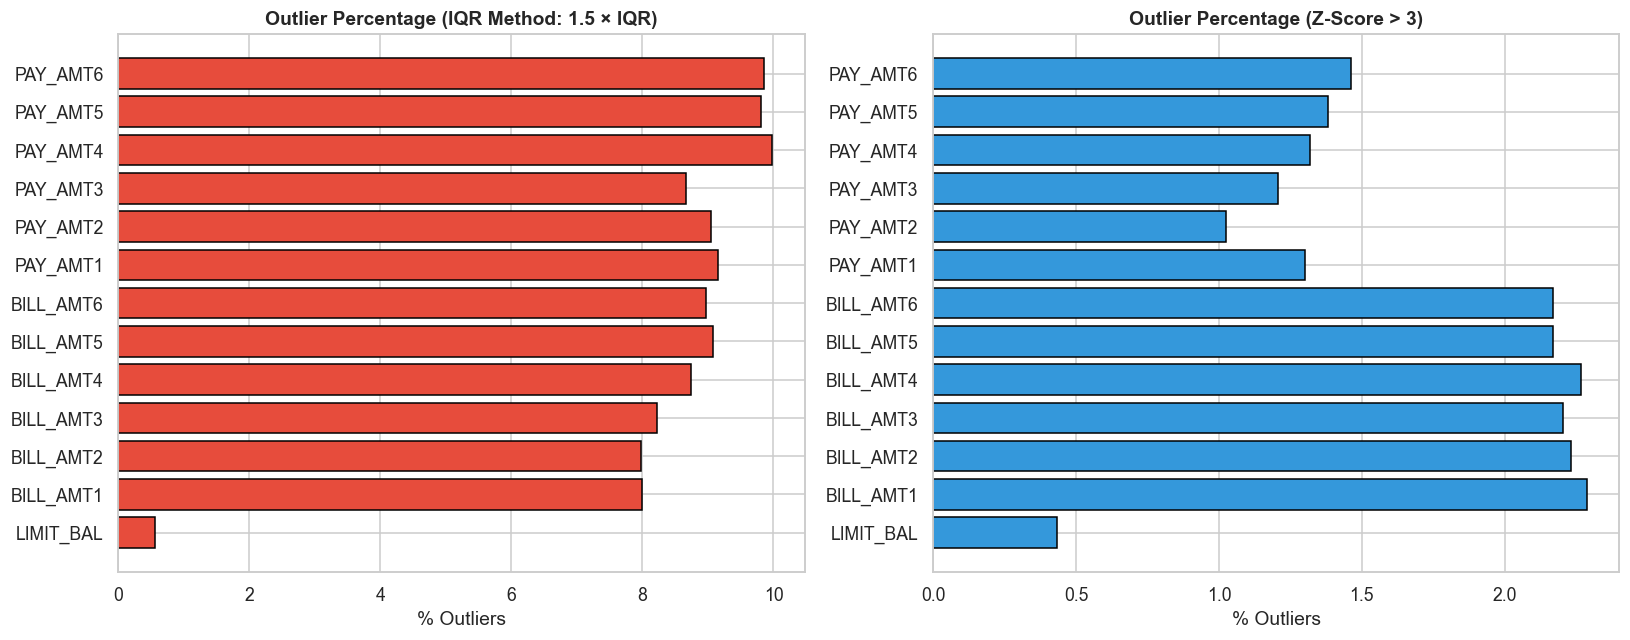

Plot saved to: outputs\eda_plots\05_outlier_percentages.png


,Feature,IQR Outliers,IQR %,Z>3 Outliers,Z>3 %
0,LIMIT_BAL,167,0.556667,130,0.433333
1,BILL_AMT1,2400,8.000000,686,2.286667
2,BILL_AMT2,2395,7.983333,670,2.233333
3,BILL_AMT3,2469,8.230000,661,2.203333
4,BILL_AMT4,2622,8.740000,680,2.266667
5,BILL_AMT5,2725,9.083333,651,2.170000
6,BILL_AMT6,2693,8.976667,651,2.170000
7,PAY_AMT1,2745,9.150000,390,1.300000
8,PAY_AMT2,2714,9.046667,307,1.023333
9,PAY_AMT3,2598,8.660000,362,1.206667


In [16]:
outlier_cols = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]

outlier_summary = []
for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    iqr_outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    iqr_pct = iqr_outliers / len(df) * 100
    
    z_scores = np.abs(stats.zscore(df[col]))
    z_outliers = (z_scores > 3).sum()
    z_pct = z_outliers / len(df) * 100
    
    outlier_summary.append({
        "Feature": col,
        "IQR Outliers": iqr_outliers,
        "IQR %": iqr_pct,
        "Z>3 Outliers": z_outliers,
        "Z>3 %": z_pct
    })

outlier_df = pd.DataFrame(outlier_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(outlier_df["Feature"], outlier_df["IQR %"], color="#e74c3c", edgecolor="black")
axes[0].set_title("Outlier Percentage (IQR Method: 1.5 × IQR)", fontweight="bold")
axes[0].set_xlabel("% Outliers")

axes[1].barh(outlier_df["Feature"], outlier_df["Z>3 %"], color="#3498db", edgecolor="black")
axes[1].set_title("Outlier Percentage (Z-Score > 3)", fontweight="bold")
axes[1].set_xlabel("% Outliers")

plt.tight_layout()
save_and_show("05_outlier_percentages")

outlier_df


## Section 6: Statistical Hypothesis Testing
Rigorous formal hypothesis tests evaluating independence and distribution shifts at significance level $\alpha = 0.05$.
- **Chi-Squared ($\chi^2$) Independence Tests**: Testing categorical features (`SEX`, `EDUCATION`, `MARRIAGE`) vs. `default`.
- **Mann-Whitney U & Welch's T-Test**: Comparing credit limit (`LIMIT_BAL`) across outcome classes.
- **Kruskal-Wallis ANOVA**: Evaluating default risk variation across age brackets.

In [17]:
alpha = 0.05

print("======================================================================")
print("1. CHI-SQUARED INDEPENDENCE TESTS (Categorical vs Target)")
print("======================================================================")
for col in ["EDUCATION", "SEX", "MARRIAGE"]:
    contingency = pd.crosstab(df[col], df["default"])
    chi2, p, dof, _ = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))
    verdict = "REJECT H0 (Significant Association)" if p < alpha else "FAIL TO REJECT H0"
    print(f"Feature: {col}")
    print(f"  chi2({dof}) = {chi2:.2f}, p-value = {p:.2e}")
    print(f"  Cramér's V = {cramers_v:.4f}")
    print(f"  Decision: {verdict} at alpha={alpha}\n")

print("======================================================================")
print("2. LIMIT_BAL DIFFERENCES (Defaulters vs Non-Defaulters)")
print("======================================================================")
non_def = df.loc[df["default"] == 0, "LIMIT_BAL"]
defaulters = df.loc[df["default"] == 1, "LIMIT_BAL"]

# Mann-Whitney U Test
u_stat, p_mw = stats.mannwhitneyu(non_def, defaulters, alternative="two-sided")
rank_biserial = 1 - (2 * u_stat) / (len(non_def) * len(defaulters))
print(f"Mann-Whitney U Test: U = {u_stat:,.0f}, p-value = {p_mw:.2e}")
print(f"  Rank-Biserial Correlation r = {rank_biserial:.4f}")
print(f"  Non-defaulter mean: NT${non_def.mean():,.0f} vs Defaulter mean: NT${defaulters.mean():,.0f}")
print(f"  Decision: {'REJECT H0 (Distributions Differ)' if p_mw < alpha else 'FAIL TO REJECT H0'}\n")

# Welch's T-Test
t_stat, p_t = stats.ttest_ind(non_def, defaulters, equal_var=False)
pooled_sd = np.sqrt(((len(non_def)-1)*non_def.std()**2 + (len(defaulters)-1)*defaulters.std()**2) / (len(non_def) + len(defaulters) - 2))
cohens_d = (non_def.mean() - defaulters.mean()) / pooled_sd
print(f"Welch's t-test: t = {t_stat:.4f}, p-value = {p_t:.2e}")
print(f"  Cohen's d = {cohens_d:.4f} (Small-to-moderate effect)")
print(f"  Decision: {'REJECT H0 (Means Differ)' if p_t < alpha else 'FAIL TO REJECT H0'}\n")

print("======================================================================")
print("3. KRUSKAL-WALLIS ANOVA (Default Across Age Groups)")
print("======================================================================")
df["AGE_GROUP"] = pd.cut(df["AGE"], bins=[20, 30, 40, 50, 60, 80], labels=["21-30", "31-40", "41-50", "51-60", "61-80"])
groups = [g["default"].values for _, g in df.groupby("AGE_GROUP", observed=True)]
h_stat, p_kw = stats.kruskal(*groups)
eta_sq = (h_stat - len(groups) + 1) / (len(df) - len(groups))
print(f"Kruskal-Wallis Test: H = {h_stat:.4f}, p-value = {p_kw:.2e}")
print(f"  Eta-squared (approx) = {eta_sq:.4f}")
print(f"  Decision: {'REJECT H0 (Default rate differs significantly by age group)' if p_kw < alpha else 'FAIL TO REJECT H0'}")
df.drop(columns=["AGE_GROUP"], inplace=True)


1. CHI-SQUARED INDEPENDENCE TESTS (Categorical vs Target)
Feature: EDUCATION
  chi2(6) = 163.22, p-value = 1.23e-32
  Cramér's V = 0.0738
  Decision: REJECT H0 (Significant Association) at alpha=0.05

Feature: SEX
  chi2(1) = 47.71, p-value = 4.94e-12
  Cramér's V = 0.0399
  Decision: REJECT H0 (Significant Association) at alpha=0.05

Feature: MARRIAGE
  chi2(3) = 35.66, p-value = 8.83e-08
  Cramér's V = 0.0345
  Decision: REJECT H0 (Significant Association) at alpha=0.05

2. LIMIT_BAL DIFFERENCES (Defaulters vs Non-Defaulters)
Mann-Whitney U Test: U = 95,786,286, p-value = 1.23e-189
  Rank-Biserial Correlation r = -0.2356
  Non-defaulter mean: NT$178,100 vs Defaulter mean: NT$130,110
  Decision: REJECT H0 (Distributions Differ)

Welch's t-test: t = 28.9516, p-value = 3.36e-178
  Cohen's d = 0.3743 (Small-to-moderate effect)
  Decision: REJECT H0 (Means Differ)

3. KRUSKAL-WALLIS ANOVA (Default Across Age Groups)
Kruskal-Wallis Test: H = 37.9522, p-value = 1.15e-07
  Eta-squared (appro

## Section 7: Feature Relationships
Deep-dive into payment delay patterns over time, repayment amounts vs billed amounts, and credit utilization ratios.

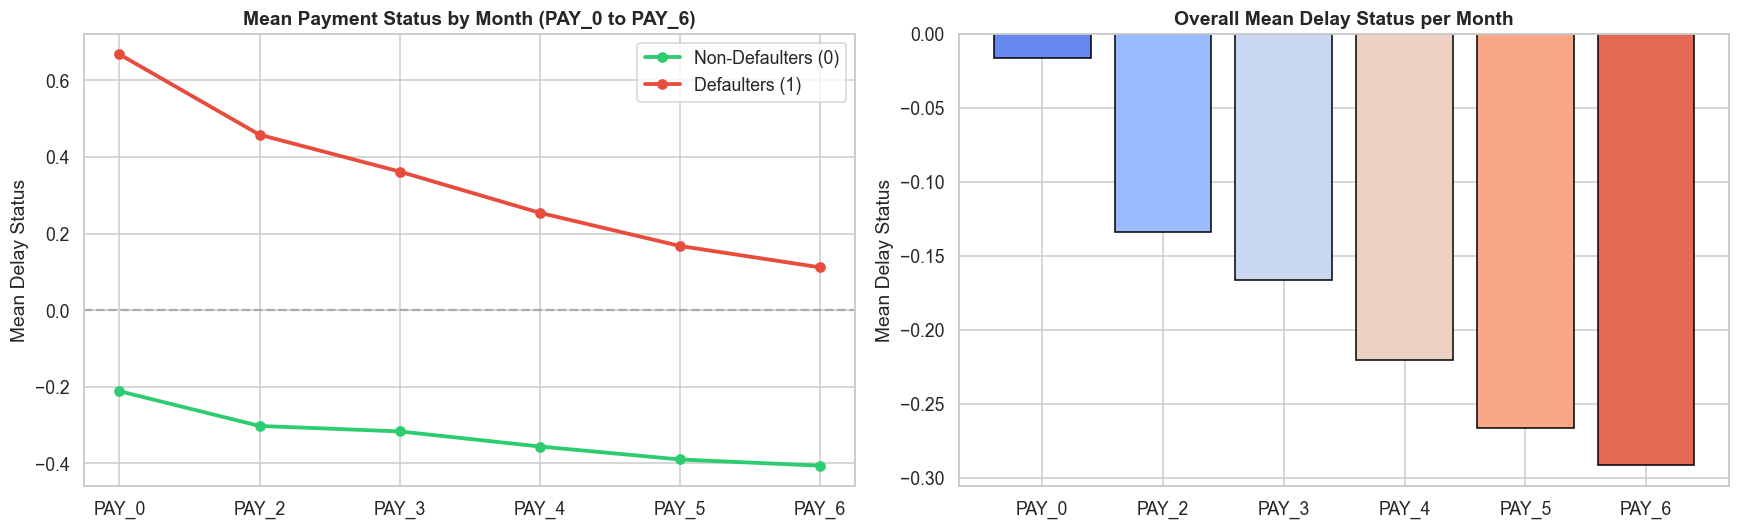

Plot saved to: outputs\eda_plots\07_payment_delay_trends.png


In [18]:
# Payment Delay Trends over 6 Months
pay_cols = [c for c in df.columns if c.startswith("PAY_") and c.replace("PAY_", "").isdigit()]
pay_cols = sorted(pay_cols, key=lambda x: int(x.split("_")[1]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for label, grp in df.groupby("default"):
    means = grp[pay_cols].mean()
    color = "#e74c3c" if label == 1 else "#2ecc71"
    lbl = "Defaulters (1)" if label == 1 else "Non-Defaulters (0)"
    axes[0].plot(range(len(pay_cols)), means.values, marker="o", linewidth=2.5, color=color, label=lbl)

axes[0].set_xticks(range(len(pay_cols)))
axes[0].set_xticklabels(pay_cols)
axes[0].axhline(0, color="gray", linestyle="--", alpha=0.5)
axes[0].set_title("Mean Payment Status by Month (PAY_0 to PAY_6)", fontweight="bold")
axes[0].set_ylabel("Mean Delay Status")
axes[0].legend()

# Bar chart of mean delays
axes[1].bar(range(len(pay_cols)), df[pay_cols].mean().values, color=sns.color_palette("coolwarm", len(pay_cols)), edgecolor="black")
axes[1].set_xticks(range(len(pay_cols)))
axes[1].set_xticklabels(pay_cols)
axes[1].set_title("Overall Mean Delay Status per Month", fontweight="bold")
axes[1].set_ylabel("Mean Delay Status")

plt.tight_layout()
save_and_show("07_payment_delay_trends")


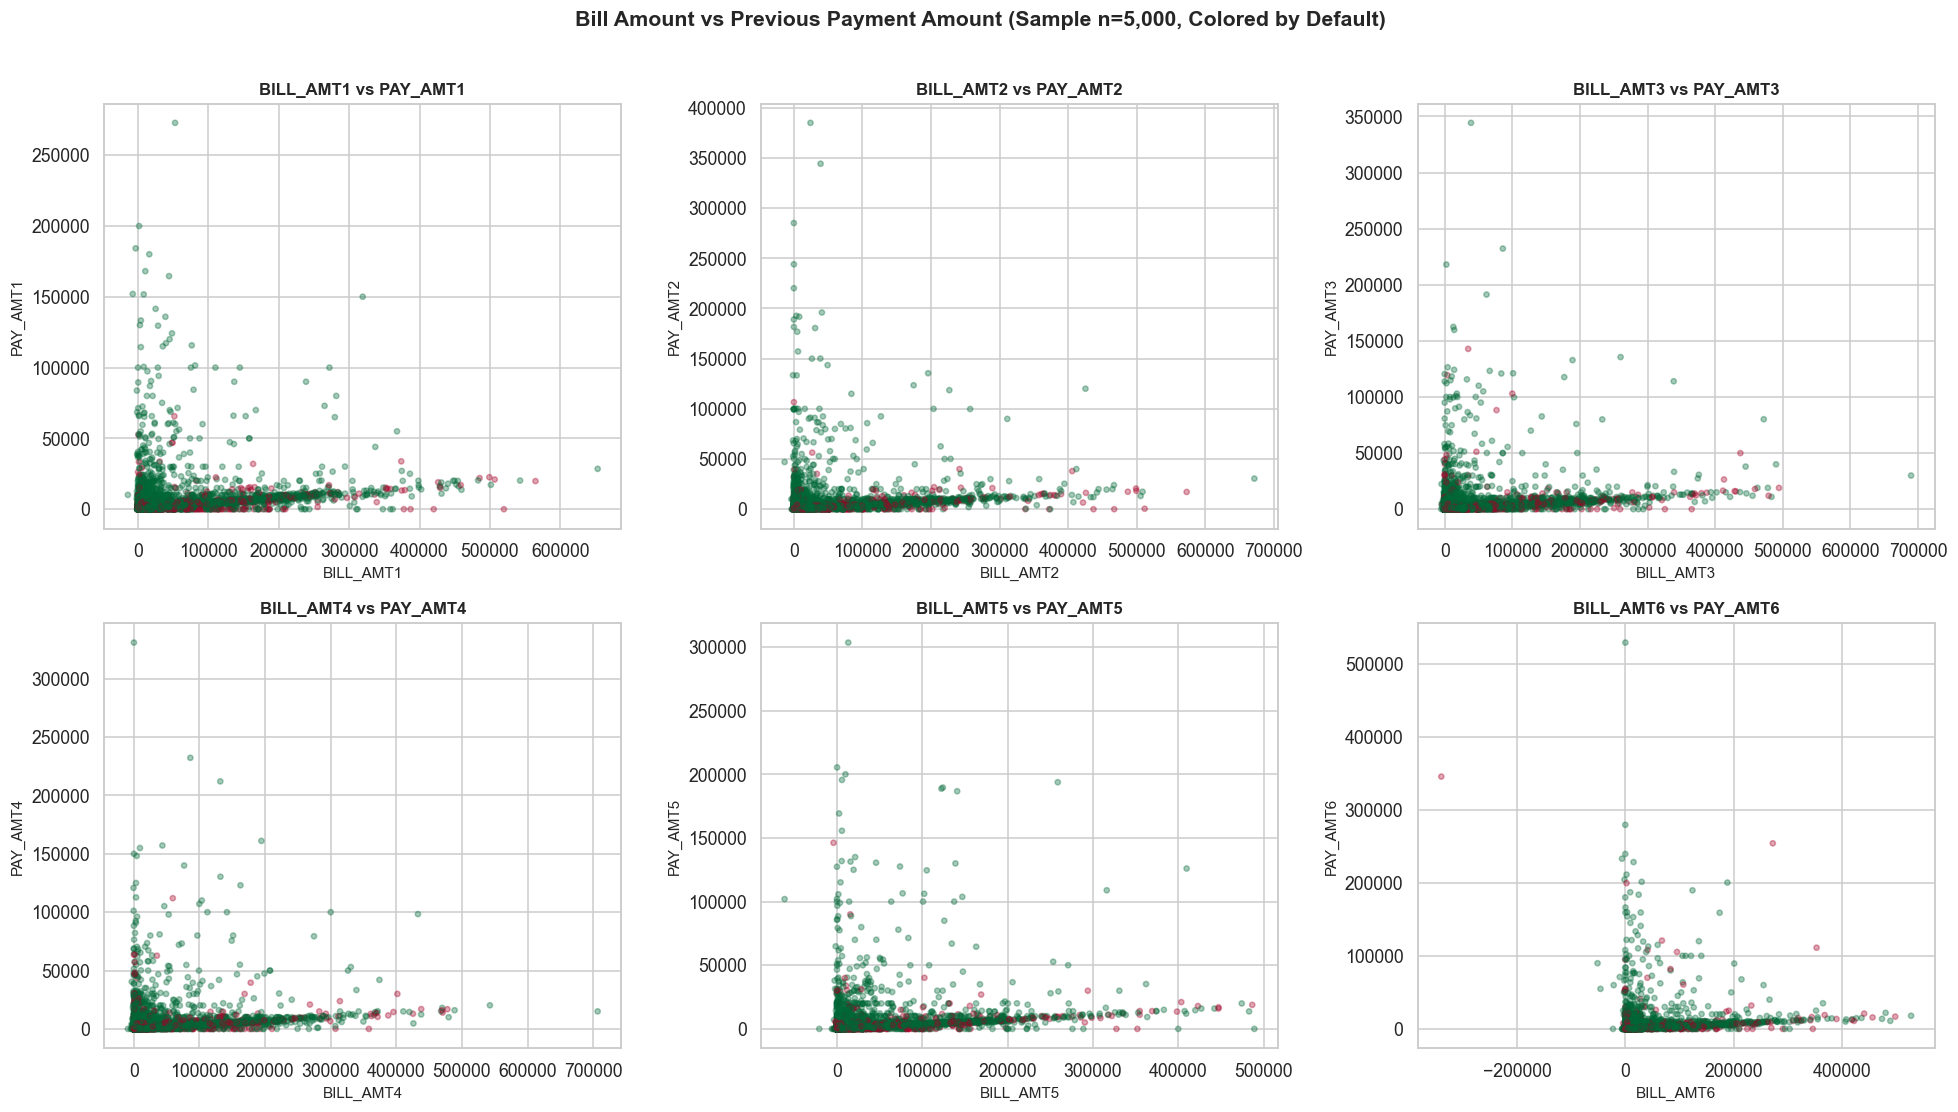

Plot saved to: outputs\eda_plots\07_bill_vs_payment_scatter.png


In [19]:
# Bill Amount vs Payment Amount Scatter (Months 1 to 6)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Sample 5,000 observations for responsive rendering
sample_df = df.sample(5000, random_state=42)

for i in range(1, 7):
    b_col = f"BILL_AMT{i}"
    p_col = f"PAY_AMT{i}"
    axes[i-1].scatter(sample_df[b_col], sample_df[p_col], c=sample_df["default"], cmap="RdYlGn_r", alpha=0.35, s=12)
    axes[i-1].set_xlabel(b_col, fontsize=10)
    axes[i-1].set_ylabel(p_col, fontsize=10)
    axes[i-1].set_title(f"{b_col} vs {p_col}", fontsize=11, fontweight="bold")

plt.suptitle("Bill Amount vs Previous Payment Amount (Sample n=5,000, Colored by Default)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
save_and_show("07_bill_vs_payment_scatter")


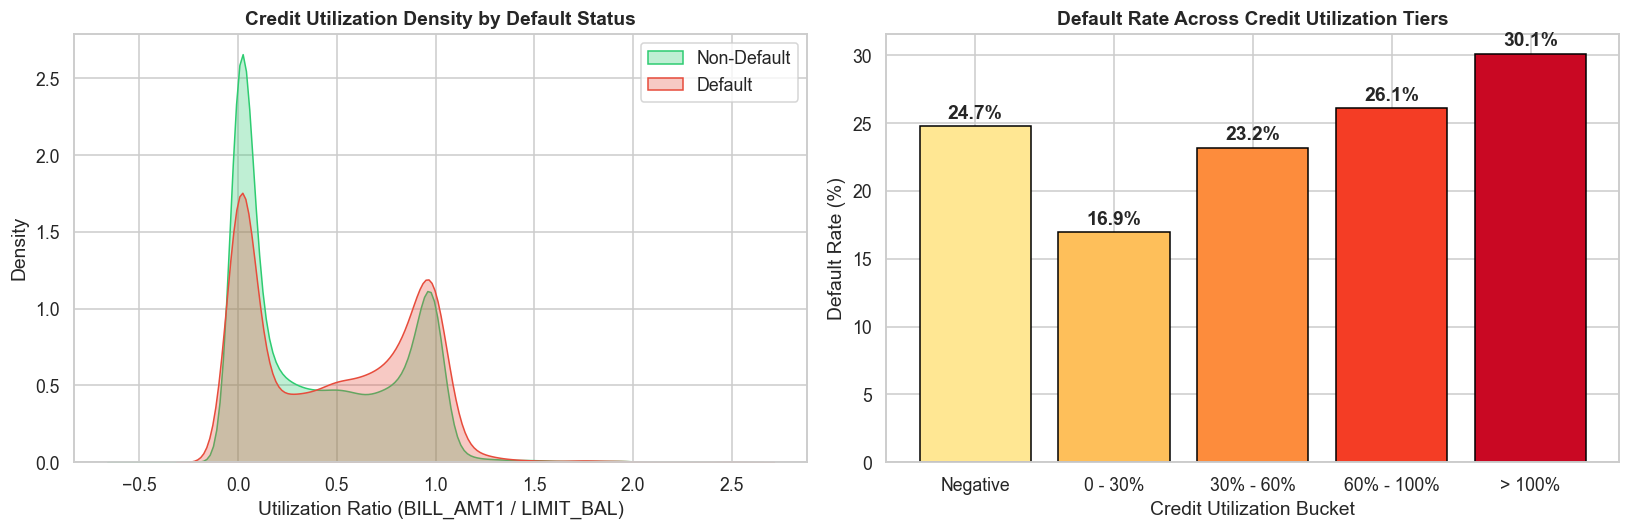

Plot saved to: outputs\eda_plots\07_utilization_ratio.png


In [20]:
# Credit Utilization Ratio Analysis (BILL_AMT1 / LIMIT_BAL)
df["utilization_ratio"] = df["BILL_AMT1"] / (df["LIMIT_BAL"] + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for label, color, lbl in [(0, "#2ecc71", "Non-Default"), (1, "#e74c3c", "Default")]:
    subset = df.loc[df["default"] == label, "utilization_ratio"].clip(-0.5, 2.5)
    sns.kdeplot(subset, ax=axes[0], color=color, label=lbl, fill=True, alpha=0.3)

axes[0].set_title("Credit Utilization Density by Default Status", fontweight="bold")
axes[0].set_xlabel("Utilization Ratio (BILL_AMT1 / LIMIT_BAL)")
axes[0].legend()

# Binned utilization vs default rate
df["util_bin"] = pd.cut(df["utilization_ratio"], bins=[-np.inf, 0, 0.3, 0.6, 1.0, np.inf], labels=["Negative", "0 - 30%", "30% - 60%", "60% - 100%", "> 100%"])
util_grp = df.groupby("util_bin", observed=True)["default"].agg(["mean", "count"])

bars = axes[1].bar(util_grp.index.astype(str), util_grp["mean"] * 100, color=sns.color_palette("YlOrRd", len(util_grp)), edgecolor="black")
for bar, (_, row) in zip(bars, util_grp.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{row['mean']*100:.1f}%", ha="center", va="bottom", fontweight="bold")

axes[1].set_title("Default Rate Across Credit Utilization Tiers", fontweight="bold")
axes[1].set_ylabel("Default Rate (%)")
axes[1].set_xlabel("Credit Utilization Bucket")

plt.tight_layout()
save_and_show("07_utilization_ratio")

df.drop(columns=["utilization_ratio", "util_bin"], inplace=True)


## Section 8: Key Findings Summary & Strategic Recommendations

### 1. Key Empirical Findings
- **Target Imbalance**: 22.1% default rate (6,636 defaults vs 23,364 non-defaults). Evaluation metrics must prioritize **PR-AUC, ROC-AUC, and F1-score** rather than raw accuracy.
- **Dominance of Recent Payment Delay (`PAY_0`)**: Repayment status in September 2005 (`PAY_0`) is by far the single most predictive feature ($r = +0.325$). A delay of $\ge 2$ months escalates default rate past 50%.
- **Credit Limit Discrepancy**: Defaulters exhibit significantly lower median credit limits (NT\$130k vs NT\$178k, $p = 1.23 \times 10^{-189}$ via Mann-Whitney U).
- **Undocumented Categoricals**: `EDUCATION` includes invalid codes 0, 5, 6 (1.15% of data), and `MARRIAGE` includes code 0 (0.18%). Both should be merged into category 4 ("Other") or 3 ("Other").
- **Collinearity Among Bill Statements**: `BILL_AMT1` through `BILL_AMT6` display extreme inter-correlations ($r > 0.85$), demanding feature aggregation (e.g., mean bill, bill growth rate) to prevent multicollinearity in linear models.
- **Utilization Ratio Dynamics**: Clients with utilization exceeding 100% of their credit limit default at 30.1%, double the rate of low-utilization accounts (16.9%).

### 2. Feature Engineering Recommendations
1. **Utilization Ratio**: Compute `BILL_AMT1 / (LIMIT_BAL + 1)` and average utilization across all 6 months.
2. **Aggregated Payment Delays**: Derive `max_payment_delay = max(PAY_0..PAY_6)` and `avg_payment_delay = mean(PAY_0..PAY_6)`.
3. **Delay Indicator**: Binary flag `has_delayed_payment = (any(PAY_X > 0))` and integer count `num_delayed_months`.
4. **Payment-to-Bill Ratio**: `PAY_AMT1 / (BILL_AMT1 + 1)` to capture repayment capacity.
5. **Total Spending & Payments**: Sum of bills `total_bill = sum(BILL_AMT1..6)` and payments `total_payment = sum(PAY_AMT1..6)`.
6. **Payment Consistency**: Standard deviation of `PAY_AMT` over the 6-month period.
7. **Monetary Transformations**: Apply logarithmic transformation $\log(1 + x)$ to heavily skewed `PAY_AMT` and `BILL_AMT` fields.

### 3. Modeling Strategy Recommendations
1. **Resampling / Cost-Sensitive Learning**: Utilize **SMOTE** (Synthetic Minority Over-sampling Technique) or configure algorithm-level class weights (`scale_pos_weight` in XGBoost, `class_weight='balanced'` in Random Forest / Logistic Regression).
2. **Cross-Validation Scheme**: Implement 5-fold Stratified K-Fold CV to preserve the 22.1% default ratio across splits.
3. **Model Selection**: Evaluate **Logistic Regression** (interpretable benchmark), **Random Forest** (non-linear baseline), and **XGBoost / LightGBM** (gradient boosted trees for state-of-the-art tabular performance).
4. **Decision Threshold Tuning**: Scan decision thresholds from 0.10 to 0.90 to maximize F1-score or balance recall/precision according to business cost matrices.
